# 电信客户流失预测 × 留存经济性（Telco Customer Churn）

**业务问题**：电信运营商月流失率约 26.5%。模型回答两个问题：
1. 哪些客户最可能流失（风险识别）？
2. 对谁做挽留、花多少钱、能赚回多少（财务决策）？

**分析口径声明**
- 数据集为观察期末快照，**无事件时间戳**：主切分为分层随机 80/20；另按在网月数分 cohort 报告 AUC/KS 作为时序稳定性代理。生产环境应改为按事件时间滚动切分（见 `docs/BRD.md`）。
- 电信场景无交易流水，RFM 采用代理构造：F=增值服务订阅数、M=月度费用（ARPU）、R=在网月数。
- 全部产出为分析底稿，不构成投资建议；数字需人工复核签署后使用。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.cluster import KMeans
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
import xgboost as xgb
import shap

SEED = 42  # 固定种子：分层切分/KMeans/XGBoost 全部锚定，保证复跑=复现
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import finance as fin  # noqa: E402

plt.rcParams.update({"font.sans-serif": ["Noto Sans CJK JP", "DejaVu Sans"], "axes.unicode_minus": False})
pd.set_option("display.width", 160)
print("ROOT:", ROOT)

ROOT: /workspace/fintech-ba-portfolio/02-python-churn-ltv


/root/.pyenv/versions/3.11.1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 数据加载与流失定义

流失定义：合同状态由在网转为离网（`Churn=Yes`）。`TotalCharges` 有 11 条空值（在网 0 个月的新客户），按 0 处理。

In [2]:
df = pd.read_csv(ROOT / "data/raw/Telco-Customer-Churn.csv")
# 为什么 TotalCharges 空值填 0：11 条空值全部是在网 0 个月的新客户、尚未产生累计费用——填 0 是业务事实，不是统计插补
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df.shape, "| churn rate = %.4f" % df["Churn"].mean())

(7043, 21) | churn rate = 0.2654


## 2. 切分、RFM 分群（KMeans）

- 分层随机 80/20 切分，`SEED=42` 固定；
- 分箱/标准化/KMeans 均在**全量数据**上拟合仅用于客户分群画像，不参与模型训练特征（分类模型只用 train 拟合预处理，见下）；

In [3]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["Churn"], random_state=SEED)  # 分层保持 26.5% 流失率；另按 tenure 分 cohort 报 AUC——快照数据无时间戳，cohort 是时序稳定性最接近的代理检验
FEATS = [c for c in df.columns if c not in ("customerID", "Churn")]
CAT = [c for c in FEATS if df[c].dtype == object]
NUM = [c for c in FEATS if c not in CAT]
pre = ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
                         ("num", StandardScaler(), NUM)])
Xtr = pre.fit_transform(train_df[FEATS])
Xtr = Xtr.toarray() if hasattr(Xtr, "toarray") else Xtr
Xte = pre.transform(test_df[FEATS])
Xte = Xte.toarray() if hasattr(Xte, "toarray") else Xte
ytr, yte = train_df["Churn"].values, test_df["Churn"].values

# RFM 代理：F=增值服务订阅数, M=月费, R=在网月数
# 为什么这样构造：电信无交易流水，用订阅数×月费×生命周期阶段近似 RFM；KMeans 只做客群画像、不作为模型特征（防泄漏）
svc = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
       "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rfm = df[["tenure", "MonthlyCharges"]].copy()
rfm["F_services"] = (df[svc] == "Yes").sum(axis=1)
km4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(StandardScaler().fit_transform(rfm))
df["cluster"] = km4.labels_
order = df.groupby("cluster")["Churn"].mean().sort_values(ascending=False).index
df["cluster"] = df["cluster"].map({o: i for i, o in enumerate(order)})
print(df.groupby("cluster")["Churn"].agg(["count", "mean"]).round(4))

         count    mean
cluster               
0         2315  0.4747
1         1557  0.2421
2         2144  0.1604
3         1027  0.0477


## 3. 客户分群画像与 Cox 比例风险模型

- 分群后计算每群流失率、ARPU 与折现 LTV；
- Cox PH：时长=在网月数，事件=流失；报告风险比 Top 系数与 PH 假设检验（Schoenfeld）。

            n  churn_rate   arpu      ltv    ltv_pool
cluster                                              
0        2315        0.47  77.60  1108.90  2567112.58
1        1557        0.24  29.89   438.03   682016.94
2        2144        0.16  92.10  1075.39  2305640.84
3        1027        0.05  31.63   371.71   381743.27


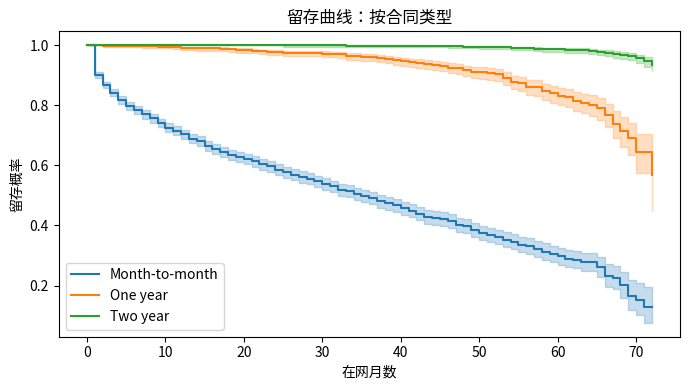

PH 假设违背最严重的 5 个变量（p<0.05 即违背）:
                                        p
cat__Contract_Two year            0.0000
cat__StreamingTV_Yes              0.0023
cat__MultipleLines_Yes            0.0032
cat__StreamingMovies_Yes          0.0049
cat__InternetService_Fiber optic  0.0296
风险比 Top 8（exp(coef)）：
                                      exp(coef)    p
covariate                                          
num__tenure                             0.3719  0.0
cat__Contract_Two year                  0.4130  0.0
num__TotalCharges                       0.5463  0.0
cat__Contract_One year                  0.5663  0.0
cat__InternetService_Fiber optic        1.5363  0.0
cat__OnlineSecurity_Yes                 0.6748  0.0
cat__PaymentMethod_Electronic check     1.4108  0.0
cat__TechSupport_Yes                    0.7329  0.0


In [4]:
kmf = KaplanMeierFitter().fit(df["tenure"], df["Churn"])
st, sp = fin.km_survival(df["tenure"].values, df["Churn"].values)
df["LTV"] = fin.discounted_ltv(df["MonthlyCharges"].values, df["tenure"].values, st, sp)
# 为什么用 KM 生存函数推 LTV（而非 ARPU×12）：挽留决策要比较"现在花 ¥70"与"未来 36 个月一串期望毛利"，必须同口径折现；ARPU×12 会把 12 年长约与月约客户估成同一价值，错误排序触达优先级
prof = df.groupby("cluster").agg(n=("Churn", "size"), churn_rate=("Churn", "mean"),
                                 arpu=("MonthlyCharges", "mean"), ltv=("LTV", "mean"))
prof["ltv_pool"] = prof["n"] * prof["ltv"]
print(prof.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in df.groupby("Contract"):
    KaplanMeierFitter().fit(g["tenure"], g["Churn"]).plot_survival_function(ax=ax, label=name)
ax.set(title="留存曲线：按合同类型", xlabel="在网月数", ylabel="留存概率")
fig.tight_layout(); fig.savefig(ROOT / "images/km_by_contract.png", dpi=150); plt.show()

cox_df = pd.DataFrame(Xtr, columns=pre.get_feature_names_out())
cox_df[["tenure", "Churn"]] = np.column_stack([train_df["tenure"].values, ytr])
cph = CoxPHFitter(penalizer=0.1).fit(cox_df, duration_col="tenure", event_col="Churn")
try:
    ph = proportional_hazard_test(cph, cox_df)
    print("PH 假设违背最严重的 5 个变量（p<0.05 即违背）:\n", ph.summary.sort_values("p")[["p"]].head(5).round(4))
except Exception as e:
    print("PH test skipped:", e)
print("风险比 Top 8（exp(coef)）：\n", cph.summary.sort_values("coef", key=abs, ascending=False)[["exp(coef)", "p"]].head(8).round(4))

## 4. 分类模型：Logistic Regression vs XGBoost challenger

以 AUC / KS / PR-AUC 评估；KS=max(TPR-FPR)，风控排序力核心指标。

In [5]:
def ks_stat(y, p):
    o = np.argsort(-p); y = y[o]
    tp = np.cumsum(y) / max(y.sum(), 1); fp = np.cumsum(1 - y) / max((1 - y).sum(), 1)
    return float(np.max(tp - fp))

lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
xgbm = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.9,
                         colsample_bytree=0.9, eval_metric="auc", random_state=SEED, n_jobs=4).fit(Xtr, ytr)
rows = []
for name, m in [("LogisticRegression", lr), ("XGBoost", xgbm)]:
    p = m.predict_proba(Xte)[:, 1]
    rows.append({"model": name, "AUC": roc_auc_score(yte, p), "KS": ks_stat(yte, p),
                 "PR_AUC": average_precision_score(yte, p)})
for lo, hi in [(0, 12), (13, 36), (37, 72)]:  # 按 tenure cohort 看 AUC：各阶段排序力都 >0.75，说明模型不依赖单一生命周期区间的特征分布
    m_ = (test_df["tenure"] >= lo) & (test_df["tenure"] <= hi)
    p = xgbm.predict_proba(Xte[m_])[:, 1]
    rows.append({"model": f"XGB cohort tenure {lo}-{hi} (n={m_.sum()})", "AUC": roc_auc_score(yte[m_], p),
                 "KS": ks_stat(yte[m_], p), "PR_AUC": average_precision_score(yte[m_], p)})
met = pd.DataFrame(rows)
print(met.round(4).to_string(index=False))

                          model    AUC     KS  PR_AUC
             LogisticRegression 0.8422 0.5210  0.6350
                        XGBoost 0.8345 0.5243  0.6419
 XGB cohort tenure 0-12 (n=449) 0.7629 0.4041  0.7347
XGB cohort tenure 13-36 (n=369) 0.7981 0.4963  0.5452
XGB cohort tenure 37-72 (n=591) 0.7824 0.4509  0.2791


## 5. SHAP 可解释性

对 XGBoost 用 TreeSHAP 输出全局特征重要性（beeswarm），定位流失驱动因子。

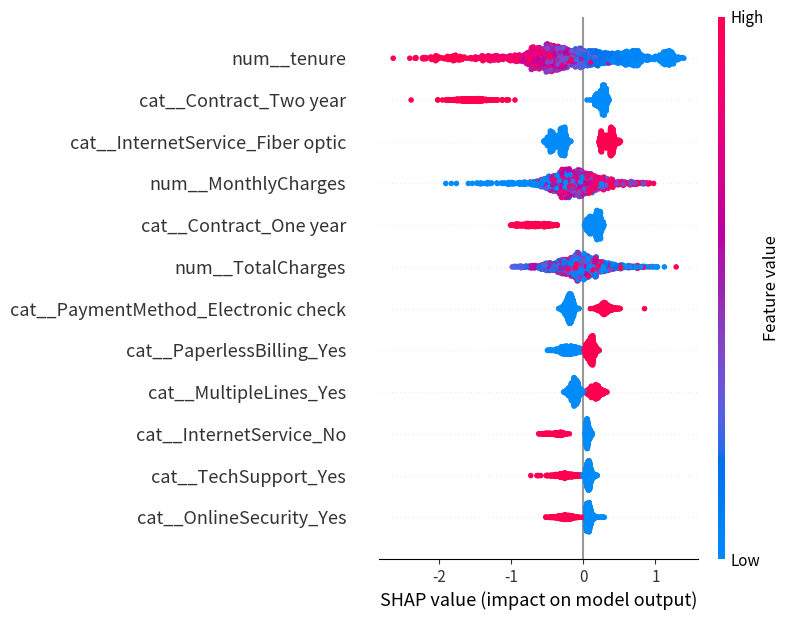

In [6]:
expl = shap.TreeExplainer(xgbm)
sv = expl.shap_values(Xte[:2000])
shap.summary_plot(sv, Xte[:2000], feature_names=list(pre.get_feature_names_out()),
                  show=False, max_display=12)
plt.tight_layout(); plt.savefig(ROOT / "images/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. 财务影响层：LTV、收入风险敞口与挽留 ROI

**公式与假设**
- 折现期望 LTV：`LTV = Σ_{m=1..36} MonthlyCharges × 毛利率 × S(tenure+m) / (1+r)^m`（S 为 KM 生存函数，r 为月度折现率）；
- 12 个月期望收入流失 RaR：`Σ MonthlyCharges × p × 12`；
- 挽留 ROI：按期望收益 `p × 30% × LTV` 降序触达，单客户成本=触达 20 元+权益 50 元；
- **决策规则**：不以"ROI 峰值"定规模（排序后 ROI 必递减，峰值恒为 N=1，无决策意义），
  而取**累计净利润最大**的 N*（边际客户收益=边际成本 70 元的拐点），并给出固定预算方案对照。

In [7]:
p_te = xgbm.predict_proba(Xte)[:, 1]
ltv_te = fin.discounted_ltv(test_df["MonthlyCharges"].values, test_df["tenure"].values, st, sp)
rar = fin.revenue_at_risk(test_df["MonthlyCharges"].values, p_te, horizon=12)
annual_rev = test_df["MonthlyCharges"].sum() * 12
print("测试集 12 个月期望收入流失 RaR = %.0f 元，占测试集年化收入 %.2f%%" % (rar, 100 * rar / annual_rev))
roi, cost, net = fin.campaign_roi(p_te, ltv_te, uplift=0.30)
n_star = int(np.nanargmax(net))
print("净利润最大触达规模 N* = %d 人：净收益 %.0f 元，ROI %.2f，总成本 %.0f 元"
      % (n_star + 1, net[n_star], roi[n_star], cost[n_star]))
print("固定预算方案 N=200（预算 14,000 元）：净收益 %.0f 元，ROI %.2f" % (net[199], roi[199]))
res = test_df[["customerID", "tenure", "MonthlyCharges", "Contract"]].copy()
res["churn_prob"], res["LTV"] = p_te, ltv_te
res["expected_save"] = res["churn_prob"] * 0.30 * res["LTV"]
res = res.sort_values("expected_save", ascending=False)
res.head(200).to_csv(ROOT / "outputs/priority_retention_list.csv", index=False)
print(res.head(5).round(2).to_string(index=False))

测试集 12 个月期望收入流失 RaR = 330995 元，占测试集年化收入 30.55%
净利润最大触达规模 N* = 550 人：净收益 62468 元，ROI 2.62，总成本 38500 元
固定预算方案 N=200（预算 14,000 元）：净收益 42413 元，ROI 4.03
customerID  tenure  MonthlyCharges       Contract  churn_prob     LTV  expected_save
7181-BQYBV       1          102.45 Month-to-month        0.93 1570.85         437.24
1400-MMYXY       3          105.90 Month-to-month        0.91 1603.18         437.17
6861-XWTWQ       7           99.25 Month-to-month        0.96 1468.82         423.87
6023-YEBUP       3          100.95 Month-to-month        0.91 1528.24         416.39
0295-PPHDO       1           95.45 Month-to-month        0.94 1463.52         413.23


## 7. 输出与落图

saved: images x4, outputs x4


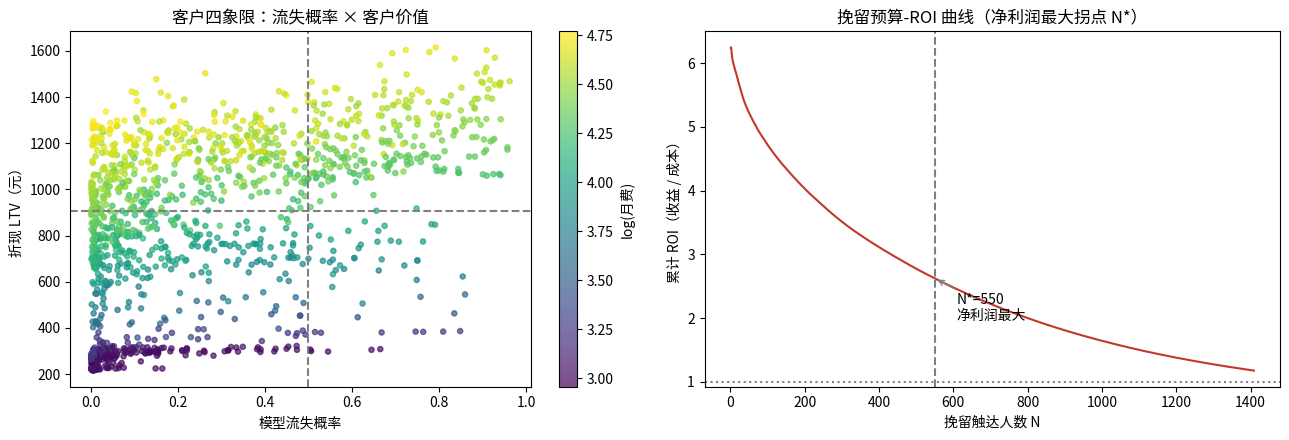

In [8]:
prof.to_csv(ROOT / "outputs/cluster_profile.csv")
met.to_json(ROOT / "outputs/metrics.json", orient="records", indent=2, force_ascii=False)
res.to_csv(ROOT / "outputs/test_scored.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = axes[0].scatter(res["churn_prob"], res["LTV"], c=np.log1p(res["MonthlyCharges"]), s=14, cmap="viridis", alpha=.7)
axes[0].axvline(0.5, ls="--", c="grey"); axes[0].axhline(np.median(res["LTV"]), ls="--", c="grey")
axes[0].set(xlabel="模型流失概率", ylabel="折现 LTV（元）", title="客户四象限：流失概率 × 客户价值")
plt.colorbar(sc, ax=axes[0], label="log(月费)")
axes[1].plot(np.arange(1, len(roi) + 1), roi, c="#c0392b", lw=1.5, label="累计 ROI")
axes[1].axvline(n_star + 1, ls="--", c="grey"); axes[1].axhline(1.0, ls=":", c="grey")
axes[1].annotate("N*=%d\n净利润最大" % (n_star + 1), xy=(n_star + 1, roi[n_star]),
                 xytext=(n_star + 60, roi[n_star] * 0.75), arrowprops=dict(arrowstyle="->", color="grey"))
axes[1].set(xlabel="挽留触达人数 N", ylabel="累计 ROI（收益 / 成本）", title="挽留预算-ROI 曲线（净利润最大拐点 N*）")
fig.tight_layout(); fig.savefig(ROOT / "images/retention_economics.png", dpi=150)
print("saved: images x4, outputs x4")

## 8. 业务建议（详见 README）

1. **资源向"高概率 × 高价值"象限倾斜**：优先挽留名单按 `churn_prob × 30% × LTV` 排序，取前 N 名直到边际 ROI 跌破 1。
2. **合同结构是第一杠杆**：Month-to-month 客户留存曲线最陡、Cox 风险比最高，推动年约转化（续约折扣）比单纯发券更根本。
3. **前 12 个月是生死线**：tenure 0-12 cohort 流失率显著更高，新手期 90 天内介入 ROI 最高。